# Getting started: smoothing and derivatives for edge detection

## Goal
Understand, step by step, **why an image is smoothed with a Gaussian before its derivatives are computed** to detect edges. This idea is the foundation of the scale space used by SIFT keypoint detection.

## Contents
1. **Setup**: load a color photo and convert it to grayscale.
2. **Image row as a 1D signal**: plot the intensity along one row of pixels, then smooth it by convolving with a Gaussian kernel (σ = 3).
3. **Chessboard image**: repeat the experiment on an image with sharp, regular edges.
4. **Raw vs. smoothed derivative** (`np.gradient`): a written comparison explains why the smoothed derivative gives more reliable thresholding, one detection per edge, and more repeatable keypoints.
5. **Derivative of the Gaussian**: compute the smoothed derivative in a single convolution.
6. **Extension to 2D**: Gaussian blur followed by Sobel filters to get the gradients `gx`, `gy` and the gradient magnitude, for σ = 3 and σ = 1.
7. **Effect of the scale σ**: blur the chessboard with increasing σ (1 to 25).

## Requirements
- Python packages: `numpy`, `opencv-python`, `matplotlib`, `scipy`.
- Images in the same folder as the notebook: `my_dog.jpg` and `chess_board.jpg`.

In [1]:
!pip install opencv-python


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Image
from scipy.stats import norm

In [4]:
def cv2_imshow(image):
    _, buf = cv2.imencode('.png', image)
    display(Image(data=buf.tobytes()))

In [9]:
img = cv2.imread('my_dog.jpg')
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
sep = np.full((img.shape[0], 30), 0, dtype=np.uint8)

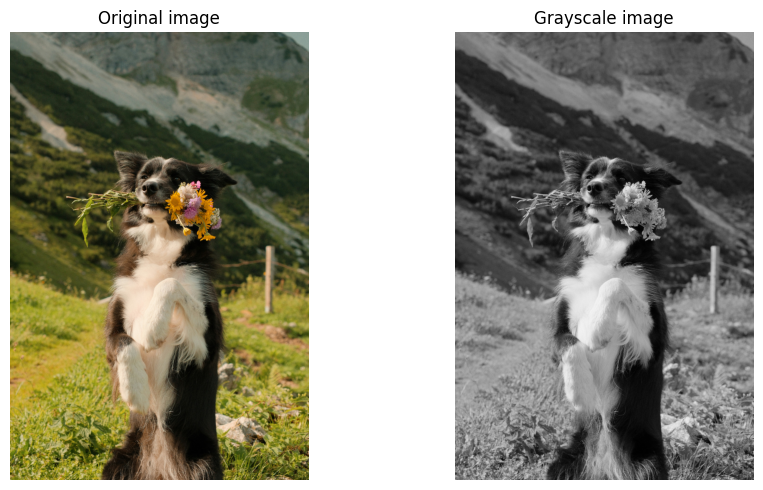

(6240, 4160, 3)


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original image")

axes[1].imshow(img_gray, cmap='gray')
axes[1].set_title("Grayscale image")

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()
print(img.shape)

A grayscale image is a **function I(x, y)**: at each position, an intensity. To plot it as a 1D signal, we take a single row of pixels (or a column):

- horizontal axis: the x position along the row (from 0 to the image width);
- vertical axis: the pixel intensity at that position.

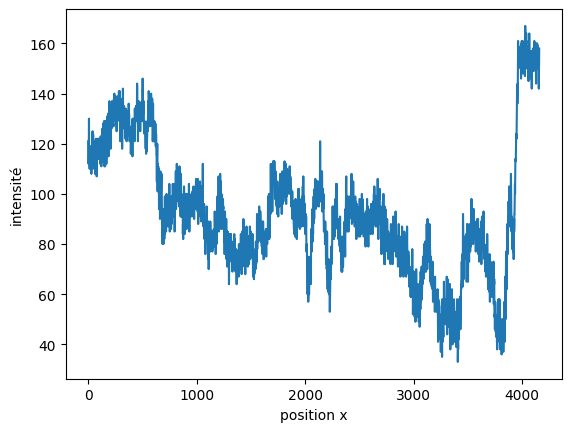

In [25]:
line = img_gray[100, :].astype(np.float64)         # row 100 of the image
plt.plot(line)
plt.xlabel("x position"); plt.ylabel("intensity")
plt.show()

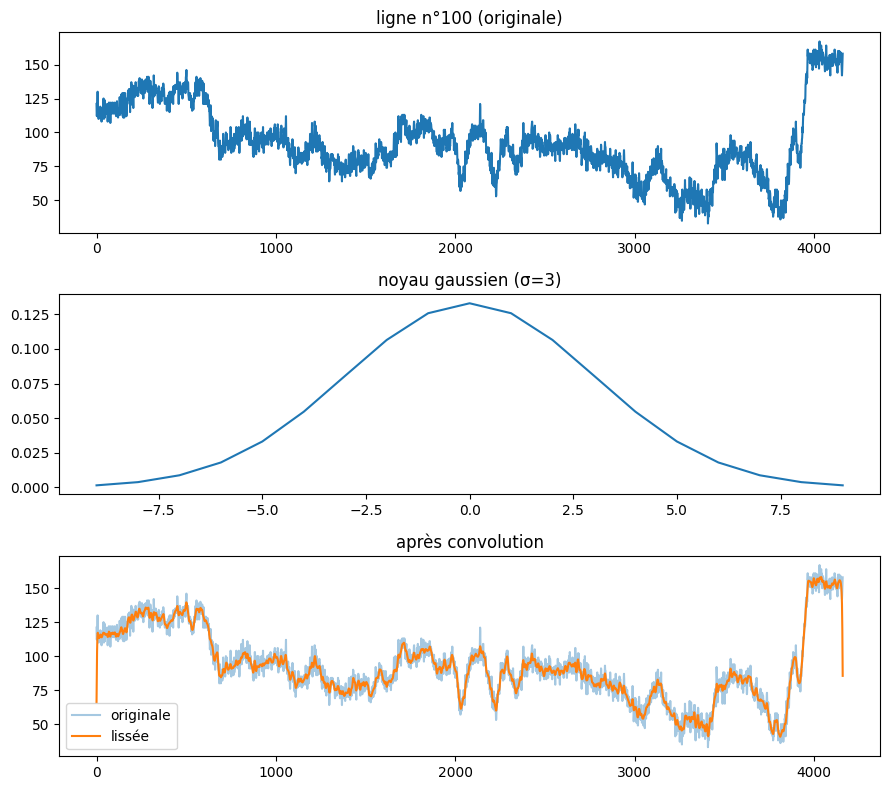

In [27]:
sigma = 3
k = np.arange(-3*sigma, 3*sigma+1) # from -3*sigma to +3*sigma: with sigma = 3, k goes from -9 to 9 (19 weight values)
kernel = norm.pdf(k, loc=0, scale=sigma)

# convolution 
smoothed_line = np.convolve(line, kernel, mode='same')

#plot
fig, ax = plt.subplots(3, 1, figsize=(9, 8))
ax[0].plot(line);        ax[0].set_title("line 100 (original)")
ax[1].plot(k, kernel);     ax[1].set_title(f"Gaussian kernel (σ={sigma})")
ax[2].plot(line, alpha=0.4, label="original")
ax[2].plot(smoothed_line, label="smoothed")
ax[2].legend(); ax[2].set_title("after convolution")
plt.tight_layout(); plt.show()

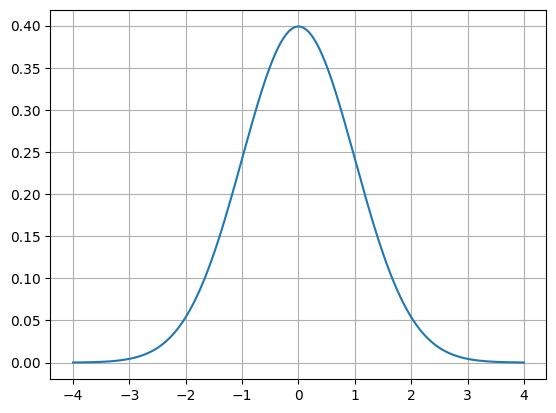

In [23]:
x = np.linspace(-4, 4, 1000)
y = norm.pdf(x, loc=0, scale=1) # loc = mean, scale = standard deviation 

plt.plot(x, y)
plt.grid()
plt.show()

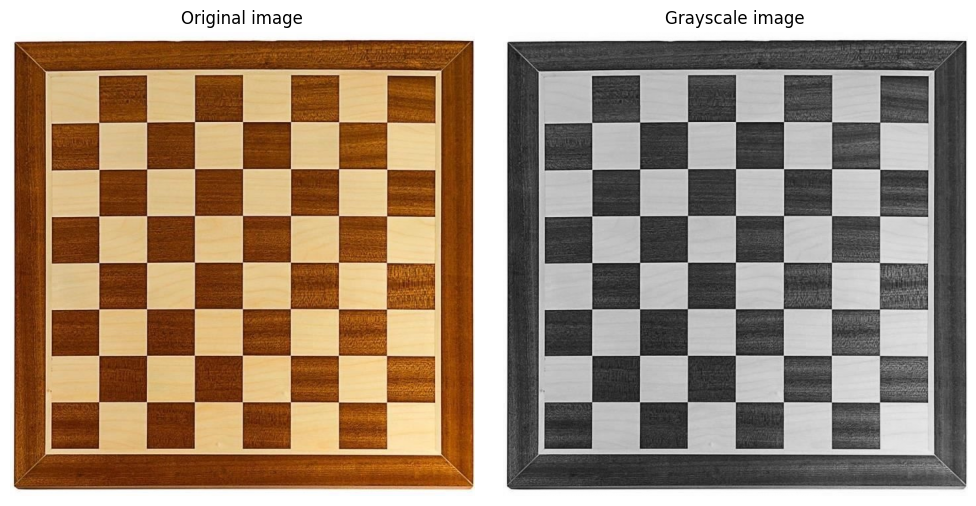

(700, 700, 3)


In [30]:
# try with an edge image
img_chess = img = cv2.imread('chess_board.jpg')
img_chess_gray = cv2.cvtColor(img_chess, cv2.COLOR_BGR2GRAY)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(cv2.cvtColor(img_chess, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original image")

axes[1].imshow(img_chess_gray, cmap='gray')
axes[1].set_title("Grayscale image")

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()
print(img_chess.shape)

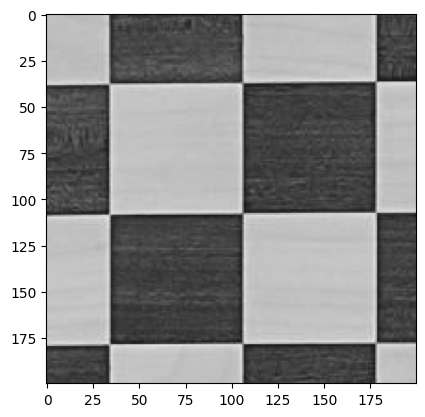

In [31]:
img_crop = img_chess_gray[100:300,100:300]

plt.imshow(cv2.cvtColor(img_crop, cv2.COLOR_BGR2RGB))


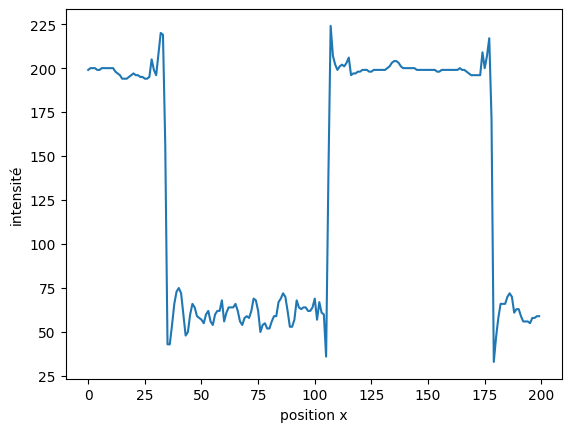

In [36]:
line = img_crop[175, :]        
plt.plot(line)
plt.xlabel("x position"); plt.ylabel("intensity")
plt.show()

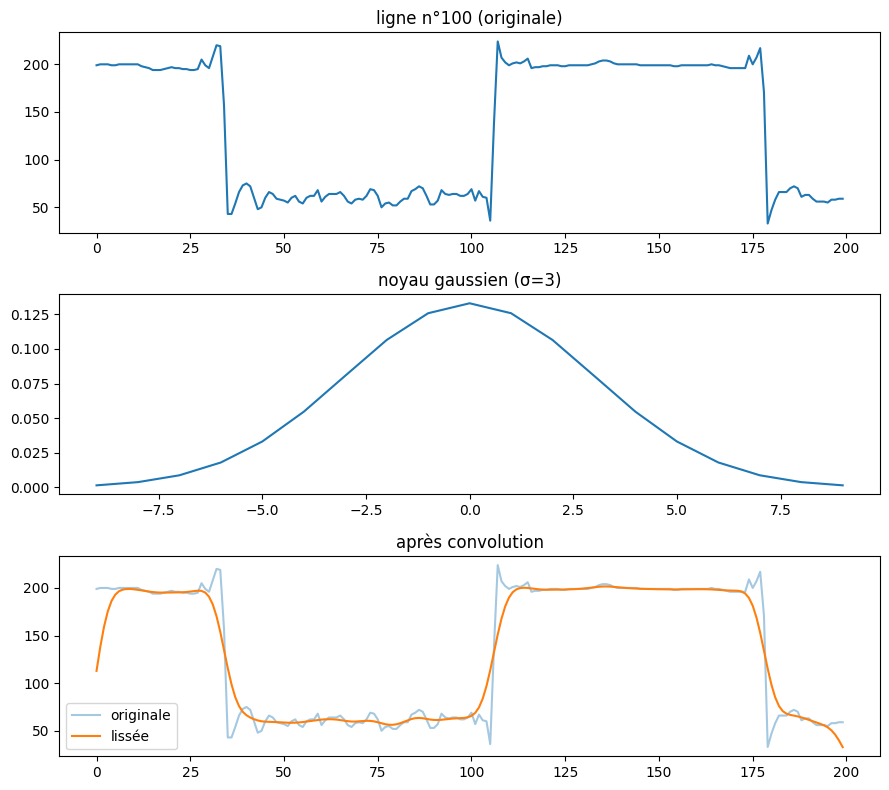

In [41]:
sigma = 3
k = np.arange(-3*sigma, 3*sigma+1)
kernel = norm.pdf(k, loc=0, scale=sigma)

# convolution 
smoothed_line = np.convolve(line, kernel, mode='same')

#plot
fig, ax = plt.subplots(3, 1, figsize=(9, 8))
ax[0].plot(line);        ax[0].set_title("line 175 (original)")
ax[1].plot(k, kernel);     ax[1].set_title(f"Gaussian kernel (σ={sigma})")
ax[2].plot(line, alpha=0.4, label="original")
ax[2].plot(smoothed_line, label="smoothed")
ax[2].legend(); ax[2].set_title("after convolution")
plt.tight_layout(); plt.show()

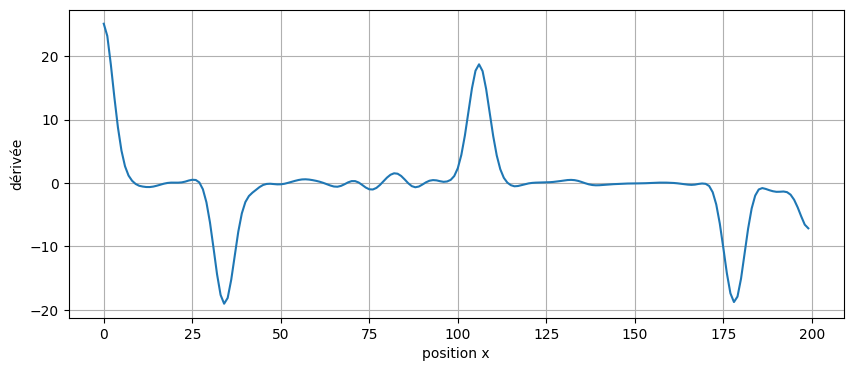

In [42]:
d_smooth = np.diff(smoothed_line)          # length N-1
# or, better:
d_smooth = np.gradient(smoothed_line)      # same length N, centered differences

plt.figure(figsize=(10, 4))
plt.plot(d_smooth)
plt.xlabel("x position"); plt.ylabel("derivative")
plt.grid(); plt.show()

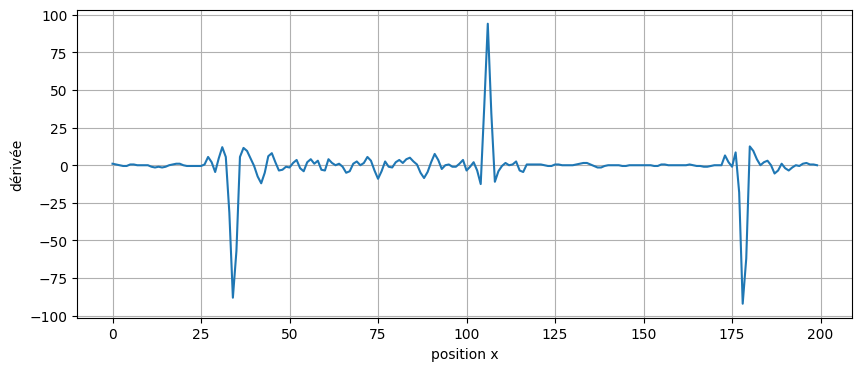

In [43]:

d_smooth = np.gradient(line)      # same length N, centered differences

plt.figure(figsize=(10, 4))
plt.plot(d_smooth)
plt.xlabel("x position"); plt.ylabel("derivative")
plt.grid(); plt.show()

## **Commentary:**
Both derivative curves share the same skeleton (a negative peak near x = 34, a positive peak near x = 106, a negative peak near x = 178). Smoothing does not create information, it cleans up the derivative.

**Raw derivative**
- The real edges are there, but surrounded by small spurious oscillations: the curve zigzags between −10 and +10 for no structural reason.
- Around a single edge there are several peaks: near x ≈ 30 the curve rises to +12, then plunges to −88 near x ≈ 34, then rises back to +12. A single edge produces one main peak and rebounds of opposite sign.
- The small peaks are narrow (1 to 2 pixels), hence fragile.

**Smoothed derivative**
- A single edge = a single clean bump, roughly 10 pixels wide, with no rebound.
- Flat areas are really flat (about 0): the real edges stand out clearly.
- The amplitude is lower (−19 instead of −88): this is expected, smoothing spreads the edge out, so the maximum slope decreases.

**Why it is easier to exploit**:

**1. Reliable thresholding.** In the raw curve, spurious oscillations reach ±10 and a small real edge could have an amplitude of the same order: it is impossible to choose a threshold that keeps one and rejects the other. In the smoothed curve, the noise drops to ±1 and the real edges reach ±18: a threshold at 5 or 10 separates them cleanly.

**2. One edge = one maximum.** To locate an edge, we look for the local maximum of |derivative|. In the raw curve, this maximum is surrounded by false secondary maxima (the rebounds). In the smoothed curve, there is a single peak, hence a single detection per edge.

**3. Stable detection.** With slightly different noise (another photo of the same scene), the spurious peaks of the raw curve change position and size, whereas the bumps of the smoothed curve stay roughly the same. This is the **repeatability** of keypoints.

**4. Structures have a size.** The width of the bump (~10 px) reflects how much sigma spreads the edge. By changing sigma, we change the scale at which we detect: this is the principle behind SIFT's scale space.

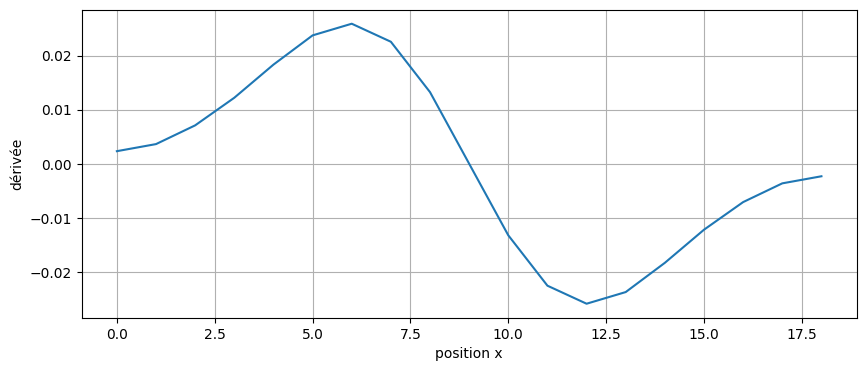

In [44]:
# another way of computing the derivative of the smoothed function 
sigma = 3
k = np.arange(-3*sigma, 3*sigma+1)
gaussian = norm.pdf(k, loc=0, scale=sigma)

d_gaussian = np.gradient(gaussian)
plt.figure(figsize=(10, 4))
plt.plot(d_gaussian)
plt.xlabel("x position"); plt.ylabel("derivative")
plt.grid(); plt.show()

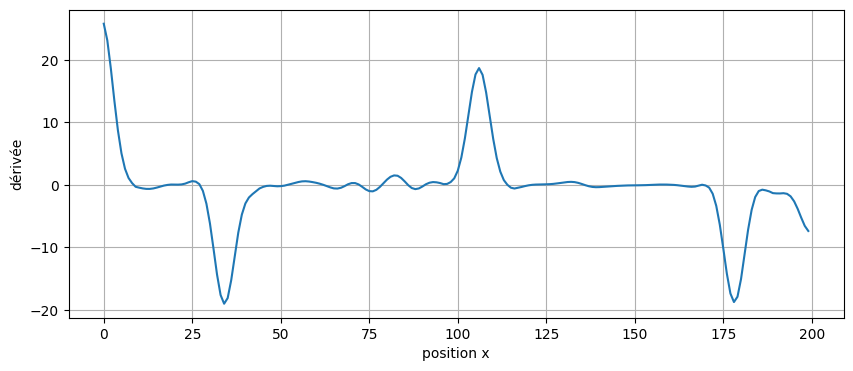

In [47]:
d_smoothed_line = np.convolve(line, d_gaussian, mode='same')
plt.figure(figsize=(10, 4))
plt.plot(d_smoothed_line)
plt.xlabel("x position"); plt.ylabel("derivative")
plt.grid(); plt.show()

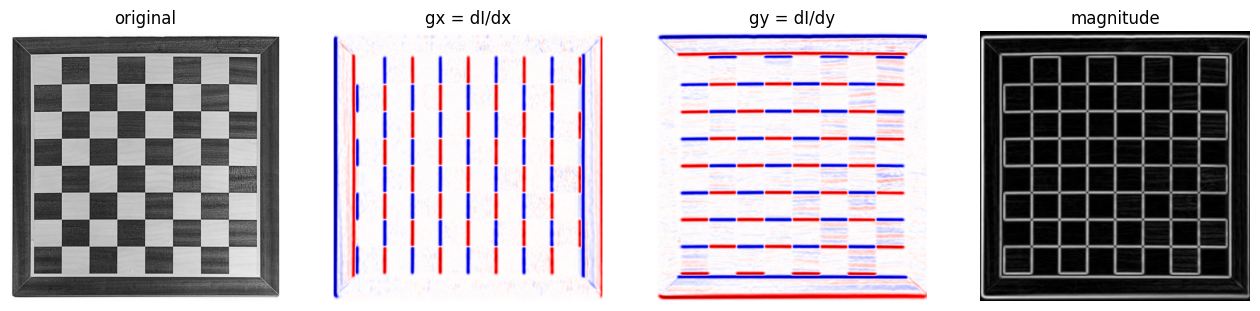

In [50]:
import numpy as np, cv2
import matplotlib.pyplot as plt

sigma = 3
blurred = cv2.GaussianBlur(img_chess_gray, (0, 0), sigma).astype(np.float64)

gx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)   # derivative along x (vertical edges)
gy = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)   # derivative along y (horizontal edges)
mag = np.hypot(gx, gy)                             # edge strength, always >= 0

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
m = np.abs(gx).max()
ax[0].imshow(img_chess_gray, cmap='gray');                ax[0].set_title("original")
ax[1].imshow(gx, cmap='seismic', vmin=-m, vmax=m);  ax[1].set_title("gx = dI/dx")
ax[2].imshow(gy, cmap='seismic', vmin=-m, vmax=m);  ax[2].set_title("gy = dI/dy")
ax[3].imshow(mag, cmap='gray');                     ax[3].set_title("magnitude")
for a in ax: a.axis('off')
plt.show()

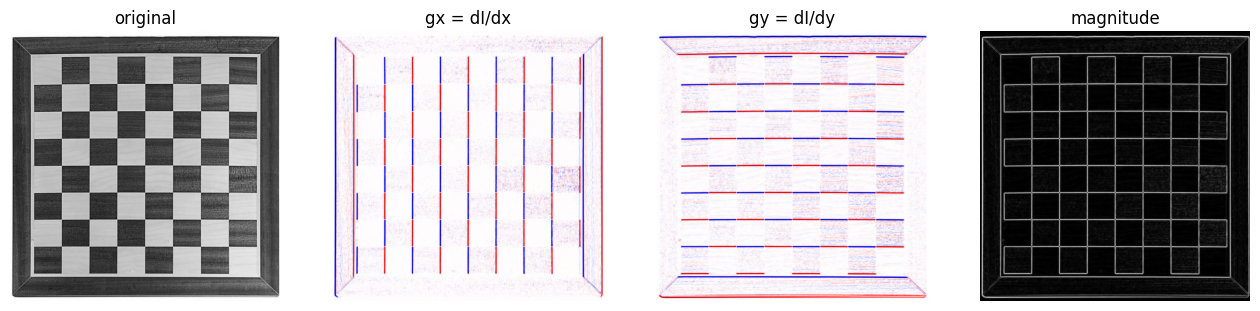

In [52]:
sigma = 1
blurred = cv2.GaussianBlur(img_chess_gray, (0, 0), sigma).astype(np.float64)

gx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)   # derivative along x (vertical edges)
gy = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)   # derivative along y (horizontal edges)
mag = np.hypot(gx, gy)                             # edge strength, always >= 0

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
m = np.abs(gx).max()
ax[0].imshow(img_chess_gray, cmap='gray');                ax[0].set_title("original")
ax[1].imshow(gx, cmap='seismic', vmin=-m, vmax=m);  ax[1].set_title("gx = dI/dx")
ax[2].imshow(gy, cmap='seismic', vmin=-m, vmax=m);  ax[2].set_title("gy = dI/dy")
ax[3].imshow(mag, cmap='gray');                     ax[3].set_title("magnitude")
for a in ax: a.axis('off')
plt.show()

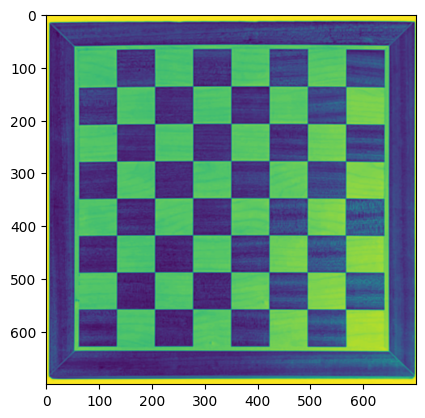

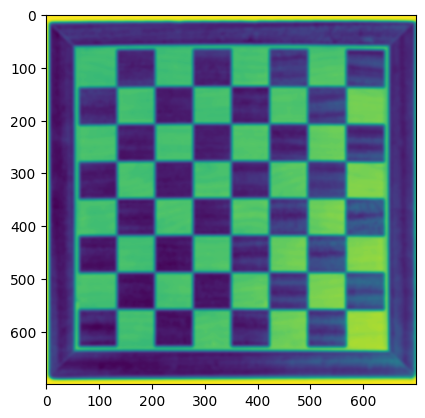

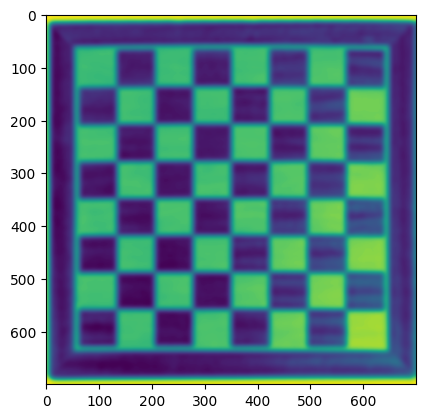

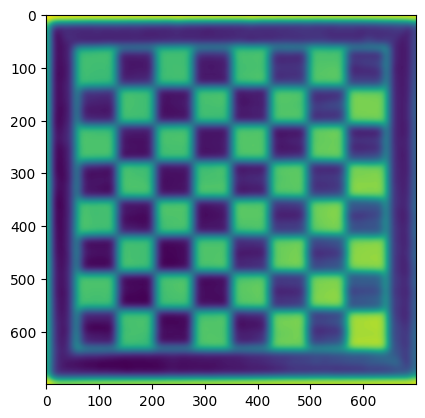

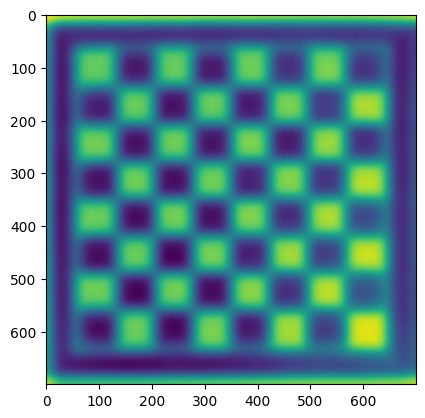

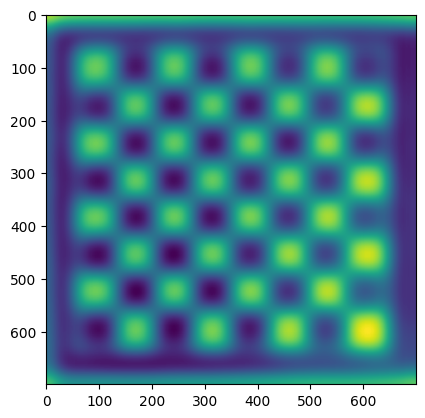

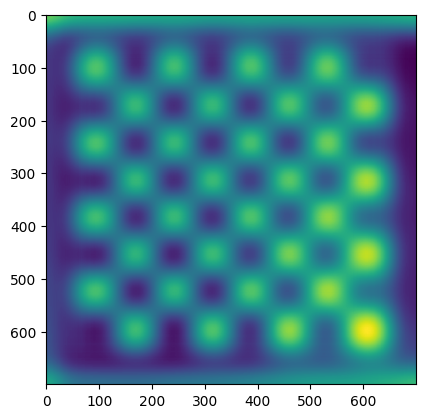

In [56]:
sigmas = [1, 3, 5, 8, 12, 18, 25]
for sigma in sigmas : 
    blurred = cv2.GaussianBlur(img_chess_gray, (0, 0), sigma).astype(np.float64)
    plt.imshow(blurred)
    plt.show()